# Keyword Baseline

BM25 with raw tokens, BM25 with stemming, 3-5 character TF-IDF. Comparison using only the training set

Provide: Selected keyword method, results

In [2]:
# libraries

import numpy as np
import pandas as pd
import nltk
import time
from collections import defaultdict
import re
import matplotlib.pyplot as plt
import json
import os

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


# finnish stemmer from NLTK
from nltk.stem.snowball import SnowballStemmer

# BM25 library
from rank_bm25 import BM25Okapi

## 1 Load Data

1. catalog_clean.csv
2. test_set_dev.csv, only requests from dev set

In [3]:
catalog = pd.read_csv('../data/clean/catalog_clean.csv')

# Keep unique products by product_number
catalog = catalog.drop_duplicates(subset=['product_number']).reset_index(drop=True)
catalog['search_text'] = catalog['search_text'].fillna(catalog['clean_label']).fillna('')


In [4]:
dev = pd.read_csv('../data/clean/test_set_dev.csv')

# Group dev set by unique query so each query has a set of acceptable gold product numbers
dev_queries = dev.groupby('clean_query').agg({
    'gold_product_number': lambda x: set(str(p) for p in x),
    'area_name': 'first',
    'request': 'first'
}).reset_index()
print(f"Catalog unique products: {len(catalog):,}")
print(f"Development unique queries: {len(dev_queries):,}")

dev_queries[['clean_query', 'area_name']].head(3)

Catalog unique products: 70,720
Development unique queries: 136


,clean_query,area_name
0,11. akkuruuviväännin – 18 v,Koneet
1,"7. akkuruuviväännin – 10,9 v",Koneet
2,adblue 10 l,"Tekniset kemikaalit/-tarvikkeet, teipit"


## 2 Evaluation

In B2B quotation requests, a customer inquiry often has more than one valid product in the catalog (for example, alternative brands like Sievi vs. Jalas, or budget vs. premium options). To evaluate how well our retrieval methods find these products, we use five complementary metrics based on measurement theory (Giner, 2023) and practical RAG benchmarks (Thinking Loop, 2025):

- **Hit@1 (Top-1 Success):** Checks if the very first result is an acceptable product. This is our main metric because a correct top-1 result can be quoted automatically without manual work.
- **Recall@5 & Recall@10:** Checks if at least one acceptable product appears in the top 5 or top 10 results. This tells us whether the candidate pool is good enough for downstream reranking or an LLM.
- **MRR (Mean Reciprocal Rank):** Measures how close to the top the first acceptable product is ($1/\text{rank}$). 
- **nDCG@5 (Normalized Discounted Cumulative Gain):** Rewards the search engine for ranking valid alternative products near the top (ranks 1–3). This is especially useful when several products could satisfy the customer's request.
- **Latency (ms/query):** Average retrieval time per query, ensuring the method is fast enough for real-world use.

**References:**
- Giner, F. (2023). *An Intrinsic Framework of Information Retrieval Evaluation Measures*. arXiv:2304.00615.
- Thinking Loop (2025). *Top 10 Retrieval Metrics for Tuning Your RAG*.

In [5]:
# function to evaluate retrieval on dev queries (with Hit@1, Recall, MRR, and nDCG)
def evaluate_method(method_name, search_func):
    """
    search_func(query_text) -> list of top-10 product numbers.
    Computes Hit@1, Recall@5, Recall@10, MRR, nDCG@5, and Latency.
    """
    t0 = time.time()
    hit1_count = 0
    hit5_count = 0
    hit10_count = 0
    rr_list = []
    ndcg5_list = []
    
    for _, row in dev_queries.iterrows():
        query = row['clean_query']
        gold_set = row['gold_product_number']
        
        # retrieve top 10
        top_results = search_func(query)
        
        # Hit@1 (Is the top-1 an acceptable product?)
        if len(top_results) > 0 and top_results[0] in gold_set:
            hit1_count += 1
            
        # Recall@5 & Recall@10 (Is at least one acceptable product in top-k?)
        if any(prod in gold_set for prod in top_results[:5]):
            hit5_count += 1
        if any(prod in gold_set for prod in top_results[:10]):
            hit10_count += 1
            
        # MRR (Rank of the first acceptable product)
        rr = 0.0
        for rank, prod in enumerate(top_results[:10], start=1):
            if prod in gold_set:
                rr = 1.0 / rank
                break
        rr_list.append(rr)
        
        # nDCG@5 (Rewards having acceptable products at top ranks)
        # DCG: sum of 1/log2(rank+1) for every hit in top 5
        dcg = sum(1.0 / np.log2(i + 1) for i, prod in enumerate(top_results[:5], start=1) if prod in gold_set)
        # Ideal DCG: best possible score if all available gold products were at the top
        ideal_hits = min(len(gold_set), 5)
        idcg = sum(1.0 / np.log2(i + 1) for i in range(1, ideal_hits + 1))
        ndcg5 = (dcg / idcg) if idcg > 0 else 0.0
        ndcg5_list.append(ndcg5)
        
    elapsed = time.time() - t0
    n = len(dev_queries)
    
    return {
        'Method': method_name,
        'Hit@1': hit1_count / n,
        'Recall@5': hit5_count / n,
        'Recall@10': hit10_count / n,
        'MRR': np.mean(rr_list),
        'nDCG@5': np.mean(ndcg5_list),
        'Latency (ms/query)': (elapsed / n) * 1000
    }


### Method 1: BM25 with raw tokens

Tokenizes catalog descriptions and queries into lowercase words and alphanumeric codes without stemming. Exact technical codes (e.g., m8x40, din912) are preserved as individual tokens.

In [6]:
#  tokenization for raw tokens
def tokenize_raw(text):
    return re.findall(r'\b\w+\b', str(text).lower())

print("Tokenizing catalog products...")

t0 = time.time()
corpus_raw = [tokenize_raw(text) for text in catalog['search_text']]
bm25_raw = BM25Okapi(corpus_raw)
index_time_raw = time.time() - t0
print(f"Indexed {len(corpus_raw):,} products in {index_time_raw:.2f} s")

# search function for BM25 raw
def search_bm25_raw(query_str):
    tokens = tokenize_raw(query_str)
    if not tokens:
        return []
    scores = bm25_raw.get_scores(tokens)
    top_indices = np.argsort(scores)[::-1][:10]
    return catalog.iloc[top_indices]['product_number'].tolist()

# evaluate Method 1 and store results
results = []
res_raw = evaluate_method("BM25 (Raw tokens)", search_bm25_raw)
res_raw['Index Time (s)'] = index_time_raw
results.append(res_raw)

# Display result
pd.DataFrame(results).round(4)

Tokenizing catalog products...
Indexed 70,720 products in 2.38 s


,Method,Hit@1,Recall@5,Recall@10,MRR,nDCG@5,Latency (ms/query),Index Time (s)
0,BM25 (Raw tokens),0.1765,0.3088,0.375,0.2377,0.2457,74.2504,2.3812


Hit@1: 0.1765 (17.7 %)
Recall@5: 0.3088 (30.9 %)
Recall@10: 0.3750 (37.5 %)
MRR: 0.2377
nDCG@5: 0.2457
Latency: ~58 ms / query

### Method 2: BM25 with finnish stemming

Applies NLTK's Snowball Finnish stemmer (SnowballStemmer("finnish")) to reduce Finnish inflected word forms (e.g., ruuvit -> ruuv, käsineet -> käsin). Technical codes without Finnish suffixes remain largely unaffected.

In [7]:
stemmer = SnowballStemmer("finnish")

def tokenize_stem(text):
    tokens = re.findall(r'\b\w+\b', str(text).lower())
    return [stemmer.stem(t) for t in tokens]
print("Tokenizing and stemming catalog products...")
t0 = time.time()
corpus_stem = [tokenize_stem(text) for text in catalog['search_text']]
bm25_stem = BM25Okapi(corpus_stem)
index_time_stem = time.time() - t0
print(f"Indexed {len(corpus_stem):,} stemmed products in {index_time_stem:.2f} s")

Tokenizing and stemming catalog products...
Indexed 70,720 stemmed products in 36.89 s


In [8]:
# search function for BM25 stemmed
def search_bm25_stem(query_str):
    tokens = tokenize_stem(query_str)
    if not tokens:
        return []
    scores = bm25_stem.get_scores(tokens)
    top_indices = np.argsort(scores)[::-1][:10]
    return catalog.iloc[top_indices]['product_number'].tolist()

In [9]:
res_stem = evaluate_method("BM25 (Finnish stemming)", search_bm25_stem)
res_stem['Index Time (s)'] = round(index_time_stem, 2)
results.append(res_stem)

pd.DataFrame(results).round(4)

,Method,Hit@1,Recall@5,Recall@10,MRR,nDCG@5,Latency (ms/query),Index Time (s)
0,BM25 (Raw tokens),0.1765,0.3088,0.3750,0.2377,0.2457,74.2504,2.3812
1,BM25 (Finnish stemming),0.1838,0.3529,0.3971,0.2478,0.2661,68.9237,36.8900


*Stemming improves*:

Hit@1: 0.1765 (17.7 %)          ->          18.8%
Recall@5: 0.3088 (30.9 %)       ->          35.3%
Recall@10: 0.3750 (37.5 %)      ->          39.7%
MRR: 0.2377                     ->          0.2478
nDCG@5: 0.2457                  ->          0.2661
Latency: ~58 ms / query         ->          57s

Indexing time increases from 2s to 24s

### Method 3: TF-IDF with 3–5 Character n-grams

Uses TfidfVectorizer with subword character n-grams within word boundaries (analyzer="char_wb", ngram_range=(3, 5)) (Lab2). Cosine similarity is computed between query vectors and the catalog matrix. This captures compound words (e.g., matching ruuvi inside kuusiokoloruuvi) and morphological variations without language-specific stemming rules.

In [10]:
print("Fitting TF-IDF Vectorizer with 3-5 character n-grams...")
t0 = time.time()

tfidf_vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), sublinear_tf=True)
catalog_tfidf = tfidf_vec.fit_transform(catalog['search_text'])
index_time_tfidf = time.time() - t0

print(f"TF-IDF matrix built: {catalog_tfidf.shape[0]:,} docs x {catalog_tfidf.shape[1]:,} features in {index_time_tfidf:.2f} s")

Fitting TF-IDF Vectorizer with 3-5 character n-grams...
TF-IDF matrix built: 70,720 docs x 332,196 features in 31.54 s


In [11]:
# search function using cosine similarity
def search_tfidf(query_str):
    q_vec = tfidf_vec.transform([query_str])
    # fast cosine similarity with pre-normalized TF-IDF vectors
    scores = (q_vec @ catalog_tfidf.T).toarray().ravel()
    top_indices = np.argsort(scores)[::-1][:10]
    return catalog.iloc[top_indices]['product_number'].tolist()

In [12]:
res_tfidf = evaluate_method("TF-IDF (3-5 Char n-grams)", search_tfidf)
res_tfidf['Index Time (s)'] = round(index_time_tfidf, 2)
results.append(res_tfidf)

pd.DataFrame(results).round(4)

,Method,Hit@1,Recall@5,Recall@10,MRR,nDCG@5,Latency (ms/query),Index Time (s)
0,BM25 (Raw tokens),0.1765,0.3088,0.3750,0.2377,0.2457,74.2504,2.3812
1,BM25 (Finnish stemming),0.1838,0.3529,0.3971,0.2478,0.2661,68.9237,36.8900
2,TF-IDF (3-5 Char n-grams),0.1471,0.3309,0.4338,0.2257,0.2408,329.0604,31.5400


Only Recall@10 improves, but all other metric depreciates.

It seems that BM25 with finnish stemming wins.

### Plot results

Comparison of Hit@1, Recall@5, Recall@10, MRR, and nDCG@5 across the three keyword retrieval methods on the development set.

<Figure size 900x500 with 0 Axes>

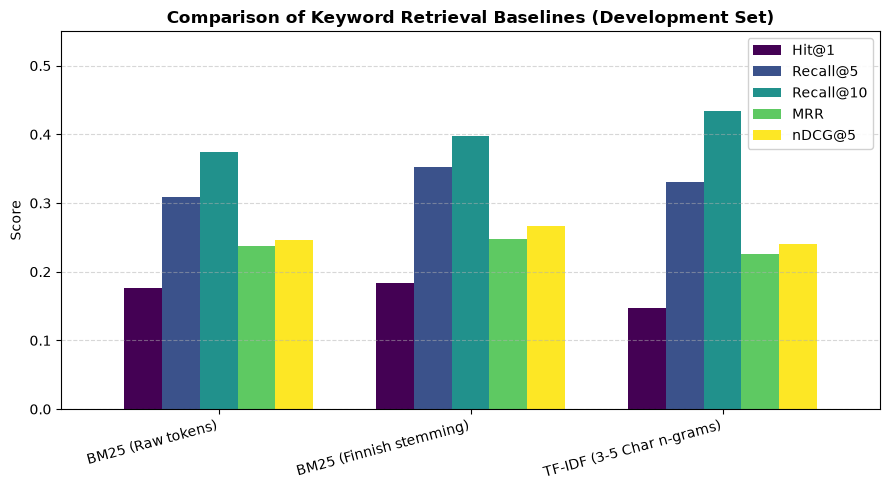

In [13]:
plt.style.use('default')
df_plot = pd.DataFrame(results).set_index('Method')[['Hit@1', 'Recall@5', 'Recall@10', 'MRR', 'nDCG@5']]
# Create bar plot
plt.figure(figsize=(9, 5))
ax = df_plot.plot(kind='bar', figsize=(9, 5), width=0.75, colormap='viridis')
plt.title("Comparison of Keyword Retrieval Baselines (Development Set)", fontsize=12, fontweight='bold')
plt.ylabel("Score", fontsize=10)
plt.xlabel("")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(loc='upper right', framealpha=0.9)
plt.tight_layout()
plt.show()

This plot confirm that BM25 with stemming is consistency stronger except Recall@10, but Hit@1 is the most important metric for us.

### Breakdown by Product Category

Inspects how each retrieval method performs across the top product categories (e.g., safety equipment vs. tools and chemicals).

In [14]:
# Evaluate query hits per category for all three methods
cat_records = []
methods = [
    ('BM25 Raw', search_bm25_raw),
    ('BM25 Stem', search_bm25_stem),
    ('TF-IDF Char', search_tfidf)
]

for method_name, search_fn in methods:
    for _, row in dev_queries.iterrows():
        top_res = search_fn(row['clean_query'])
        gold = row['gold_product_number']
        h1 = int(len(top_res) > 0 and top_res[0] in gold)
        r5 = int(any(p in gold for p in top_res[:5]))
        cat_records.append({
            'Method': method_name,
            'area_name': row['area_name'],
            'Hit@1': h1,
            'Recall@5': r5
        })

df_cat = pd.DataFrame(cat_records)

# Filter to top 5 categories
top_cats = dev_queries['area_name'].value_counts().head(5).index
cat_table = df_cat[df_cat['area_name'].isin(top_cats)].groupby(['area_name', 'Method'])[['Hit@1', 'Recall@5']].mean().unstack('Method')

print("Hit@1 by Category:")
display(cat_table['Hit@1'].round(3))

print("\nRecall@5 by Category:")
display(cat_table['Recall@5'].round(3))

Hit@1 by Category:


Method,BM25 Raw,BM25 Stem,TF-IDF Char
area_name,,,
Kiinnitystarvikkeet,0.000,0.000,0.000
Käsityökalut,0.226,0.258,0.129
Materiaalin mekaaninen työstö,0.095,0.095,0.095
"Tekniset kemikaalit/-tarvikkeet, teipit",0.143,0.143,0.143
Työturvallisuus,0.143,0.143,0.107



Recall@5 by Category:


Method,BM25 Raw,BM25 Stem,TF-IDF Char
area_name,,,
Kiinnitystarvikkeet,0.000,0.083,0.083
Käsityökalut,0.484,0.484,0.581
Materiaalin mekaaninen työstö,0.143,0.286,0.095
"Tekniset kemikaalit/-tarvikkeet, teipit",0.214,0.214,0.214
Työturvallisuus,0.214,0.250,0.250


**Conclusion**:

Based on the development set evaluation, BM25 with Finnish Stemming is selected as the winning keyword method:

- It achieves the highest Hit@1 (18.38%), Recall@5 (35.29%), MRR (0.2478), and nDCG@5 (0.2661) among the three methods.
- It runs at ~57 ms per query, which is nearly 7x faster than character n-gram TF-IDF (~389 ms).
- Category Observations:
    - Hand tools (Käsityökalut) perform best (Recall@5 = 48.4%).
    - Stemming doubles Recall@5 (14.3% -> 28.6%) in mechanical tooling, showing the importance of handling Finnish inflection.
    - Fasteners (Kiinnitystarvikkeet) are extremely challenging for all keyword methods (Hit@1 = 0%), because dense dimensional and standard codes (DIN, M8x40, A4) require semantic or reranking support.


BM25 with Finnish Stemming will serve as the lexical retriever in the upcoming hybrid pipeline (06_hybrid_rrf.ipynb).


In [15]:
# result export

output_path = '../data/clean/keyword_baseline_results.json'

# Convert category table to simple records
cat_records_summary = df_cat[df_cat['area_name'].isin(top_cats)].groupby(['area_name', 'Method'])[['Hit@1', 'Recall@5']].mean().round(3).reset_index().to_dict(orient='records')
export_data = {
    'selected_method': 'BM25 (Finnish stemming)',
    'results': results,
    'top_categories_breakdown': cat_records_summary
}
with open(output_path, 'w', encoding='utf-8') as f:
    json.dump(export_data, f, indent=2, ensure_ascii=False)
print(f"Results successfully saved to '{output_path}' ({os.path.getsize(output_path)/1024:.1f} KB)")

Results successfully saved to '../data/clean/keyword_baseline_results.json' (3.0 KB)


## Export Top-100 Stemmed BM25 Rankings as Input for Hybrid Retrieval

Identify the top 100 product numbers from the best performing keyword retrieval method for each development query and save them in a CSV file for later use in hybrid retrieval. 100 was chosen as a break of point, because two top 101 positions are unable to make the list over any product placed higher in a single list.

In [16]:
# Returns top 100 product numbers in order of ranking as list per query (analogous to previous search_bm_stem with added top_k parameter)
def search_bm25_stem_top_k(query_str, top_k=100):
    tokens = tokenize_stem(query_str)
    if not tokens:
        return []
    scores = bm25_stem.get_scores(tokens)
    top_indices = np.argsort(scores)[::-1][:top_k]
    return catalog.iloc[top_indices][['product_number','clean_label']].to_dict('records')

# Following the iteration logic of cat_records, for each query the top 100 product numbers are retrieved
bm25_stem_top100_records = []
for _, row in dev_queries.iterrows():
    top_results = search_bm25_stem_top_k(row['clean_query'], top_k=100)
    for rank, item in enumerate(top_results, start=1):
        bm25_stem_top100_records.append({
            'clean_query': row['clean_query'],
            'rank': rank,
            'product_number': item['product_number'],
            'clean_label': item['clean_label']
        })

# Saving the top 100 as CSV file
bm25_stem_top100 = pd.DataFrame(bm25_stem_top100_records)
top100_output_path = '../data/clean/bm25_stem_top100_dev.csv'
bm25_stem_top100.to_csv(top100_output_path, index=False)
print(f"Top-100 stemmed BM25 rankings saved to '{top100_output_path}' ({len(bm25_stem_top100):,} rows)")

Top-100 stemmed BM25 rankings saved to '../data/clean/bm25_stem_top100_dev.csv' (13,600 rows)
